# Representative annotated samples for paper figures

Select the highest-resolution annotated source images per task/category from CompBench and RefEdit-Bench, then display each original beside its annotation overlay. Resolution is ranked by the annotated `image_size` pixel area; ties are deterministic by sample ID. Full source images are reloaded from the Hugging Face references in the annotation JSONL files (saved crops are not used).

Configure `N_PER_TASK`, `ANNOTATION_FILES`, `OUTPUT_DIR`, and `SAVE_FIGURES` in the next cell. Set `SAVE_FIGURES = True` to export high-resolution PNG and vector PDF files under `.out/figures/representative_annotations`.

In [1]:
from pathlib import Path
import re
import warnings

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from framework.utils.project import find_project_root
from visualization import HuggingFaceRowImageLoader, load_annotations

WORKSPACE = find_project_root()
def default_annotation_file(benchmark_dir, filename):
    benchmark_dir = Path(benchmark_dir)
    runs = sorted(benchmark_dir.glob(f"run_*/{filename}"))
    if runs:
        return runs[-1]
    return benchmark_dir / filename


ANNOTATION_FILES = {
    "CompBench": default_annotation_file(
        WORKSPACE / ".out/annotation/compbench", "compbench_local_multiobject_mixed.jsonl"
    ),
    "RefEdit-Bench": default_annotation_file(
        WORKSPACE / ".out/annotation/refedit_bench", "refedit_bench_mixed.jsonl"
    ),
}
N_PER_TASK = 3
OUTPUT_DIR = WORKSPACE / ".out/figures/representative_annotations"
SAVE_FIGURES = False
FIGURE_DPI = 220

if N_PER_TASK < 1:
    raise ValueError("N_PER_TASK must be a positive integer.")
for benchmark, path in ANNOTATION_FILES.items():
    if not Path(path).is_file():
        raise FileNotFoundError(f"{benchmark} annotation JSONL not found: {path}")

/Users/nghialt3670/Projects/MMEdit/mmedit-framework/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Select the highest-resolution records per task

In [2]:
def task_name(benchmark, record):
    metadata = record.get("metadata") or {}
    if benchmark == "CompBench":
        task = metadata.get("task") or str(record.get("sample_id", "")).split(":", 1)[0]
    else:
        task = metadata.get("category") or record.get("split")
    if not task:
        raise ValueError(f"Cannot determine task/category for sample {record.get('sample_id')!r}")
    return str(task)


def annotated_image_size(record):
    references = record.get("references") or []
    if not references:
        return None
    sizes = [reference.get("region", {}).get("image_size") for reference in references]
    valid_sizes = [size for size in sizes if isinstance(size, (list, tuple)) and len(size) == 2]
    if not valid_sizes:
        return None
    width, height = map(int, valid_sizes[0])
    if width <= 0 or height <= 0:
        return None
    if any(tuple(map(int, size)) != (width, height) for size in valid_sizes[1:]):
        raise ValueError(f"Inconsistent reference image sizes for {record.get('sample_id')!r}")
    return width, height


def select_representatives(benchmark, path):
    records = load_annotations(path)
    if not records:
        raise ValueError(f"No annotation records found in {path}")
    groups = {}
    for record in records:
        sample_id = record.get("sample_id", "<unknown>")
        size = annotated_image_size(record)
        if size is None:
            warnings.warn(f"Skipping {benchmark} sample {sample_id}: no valid reference image_size.")
            continue
        groups.setdefault(task_name(benchmark, record), []).append((record, size))
    if not groups:
        raise ValueError(f"No usable annotated records with image_size in {path}")

    selected = []
    for task in sorted(groups):
        ranked = sorted(
            groups[task],
            key=lambda item: (-(item[1][0] * item[1][1]), str(item[0].get("sample_id", ""))),
        )
        if len(ranked) < N_PER_TASK:
            warnings.warn(
                f"{benchmark}/{task} has {len(ranked)} usable sample(s), fewer than "
                f"N_PER_TASK={N_PER_TASK}; displaying all available samples."
            )
        selected.extend((task, record, size) for record, size in ranked[:N_PER_TASK])
    return selected


representatives = {
    benchmark: select_representatives(benchmark, path)
    for benchmark, path in ANNOTATION_FILES.items()
}
for benchmark, samples in representatives.items():
    print(f"{benchmark}: {len(samples)} representative sample(s)")
    for task, record, (width, height) in samples:
        print(f"  {task}: {record['sample_id']} — {width}×{height} ({width * height:,} pixels)")

CompBench: 15 representative sample(s)
  add: add:001ca3cb/0/00003.png — 640×640 (409,600 pixels)
  add: add:001ca3cb/0/00005.png — 640×640 (409,600 pixels)
  add: add:001ca3cb/0/00025.png — 640×640 (409,600 pixels)
  multi_object_add: multi_object_add:02b72b8d_00002.png — 640×640 (409,600 pixels)
  multi_object_add: multi_object_add:02b72b8d_00014.png — 640×640 (409,600 pixels)
  multi_object_add: multi_object_add:02b72b8d_00016.png — 640×640 (409,600 pixels)
  multi_object_remove: multi_object_remove:02b72b8d_00002.png — 640×640 (409,600 pixels)
  multi_object_remove: multi_object_remove:02b72b8d_00014.png — 640×640 (409,600 pixels)
  multi_object_remove: multi_object_remove:02b72b8d_00016.png — 640×640 (409,600 pixels)
  remove: remove:001ca3cb/0/00002.png — 640×640 (409,600 pixels)
  remove: remove:001ca3cb/0/00004.png — 640×640 (409,600 pixels)
  remove: remove:001ca3cb/0/00006.png — 640×640 (409,600 pixels)
  replace: replace:001ca3cb/0/00010.png — 640×640 (409,600 pixels)
  repl

## Reload source images and draw annotation overlays

The selected rows are loaded in dataset/split/row order so streaming sources are not repeatedly restarted. A missing source reference or failed image load is reported with the affected sample ID.

In [3]:
def source_row_key(record):
    reference = record.get("source_ref")
    match = re.fullmatch(r"hf://(.+)/([^/]+)/([0-9]+)/([^/]+)", str(reference or ""))
    if not match:
        raise ValueError(f"Invalid or missing source_ref for {record.get('sample_id')!r}: {reference!r}")
    dataset_id, split, row_index, _field = match.groups()
    return dataset_id, split, int(row_index)


image_loader = HuggingFaceRowImageLoader()
loaded_representatives = {}
for benchmark, samples in representatives.items():
    loaded = []
    for task, record, annotated_size in sorted(
        samples, key=lambda item: source_row_key(item[1])
    ):
        try:
            source, _target = image_loader.load(record)
        except Exception as exc:
            raise RuntimeError(
                f"Could not load source image for {benchmark} sample {record.get('sample_id')!r}"
            ) from exc
        if source is None:
            raise ValueError(f"No source image available for {record.get('sample_id')!r}")
        if source.size != annotated_size:
            warnings.warn(
                f"{record.get('sample_id')}: annotation size {annotated_size} differs from "
                f"loaded source size {source.size}; using the annotation coordinates as stored."
            )
        loaded.append((task, record, source))
    loaded_representatives[benchmark] = loaded

print("Loaded selected source images:", {name: len(rows) for name, rows in loaded_representatives.items()})

Loaded selected source images: {'CompBench': 15, 'RefEdit-Bench': 6}


## Display and optionally export paper figures

Each row shows the original and the same image with all annotated reference boxes and tokens. Change the role palette below if it better matches the figure's visual style.




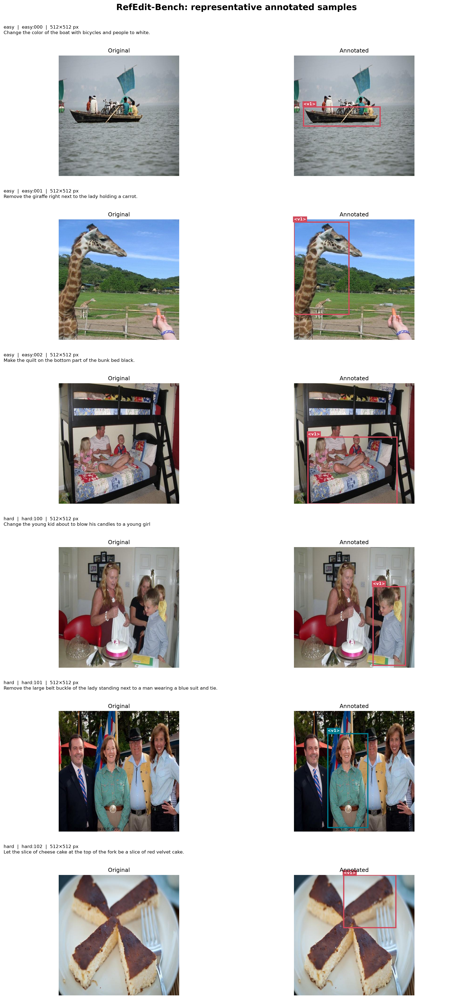

In [4]:
ROLE_COLORS = {
    "target": "#d1495b",
    "anchor": "#00798c",
    "source": "#edae49",
    "context": "#30638e",
}


def draw_representative_figure(benchmark, samples):
    if not samples:
        raise ValueError(f"No selected samples for {benchmark}")
    rows = len(samples)
    fig = plt.figure(figsize=(13, max(4.0, 4.6 * rows)), dpi=FIGURE_DPI, layout="constrained")
    grid = fig.add_gridspec(rows * 2, 2, height_ratios=[0.25, 1.0] * rows)
    fig.suptitle(f"{benchmark}: representative annotated samples", fontsize=17, fontweight="bold")

    for index, (task, record, source) in enumerate(samples):
        header = fig.add_subplot(grid[index * 2, :])
        header.axis("off")
        width, height = source.size
        instruction = str(record.get("original_instruction", "")).replace("\n", " ").strip()
        header.text(
            0.0, 0.5,
            f"{task}  |  {record.get('sample_id')}  |  {width}×{height} px\n{instruction}",
            ha="left", va="center", fontsize=9, wrap=True,
        )

        original_axis = fig.add_subplot(grid[index * 2 + 1, 0])
        annotated_axis = fig.add_subplot(grid[index * 2 + 1, 1])
        original_axis.imshow(source)
        annotated_axis.imshow(source)
        original_axis.set_title("Original", fontsize=11)
        annotated_axis.set_title("Annotated", fontsize=11)
        references = record.get("references") or []
        if not references:
            warnings.warn(f"No references to draw for {record.get('sample_id')!r}")
        for reference in references:
            region = reference.get("region") or {}
            box = region.get("bbox_xyxy")
            if not isinstance(box, (list, tuple)) or len(box) != 4:
                warnings.warn(
                    f"Skipping invalid box for {record.get('sample_id')!r} / {reference.get('token')!r}"
                )
                continue
            x0, y0, x1, y1 = map(float, box)
            color = ROLE_COLORS.get(reference.get("role"), "#00798c")
            annotated_axis.add_patch(
                Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor=color, linewidth=2.4)
            )
            annotated_axis.text(
                x0, max(0, y0 - 3), str(reference.get("token", "ref")),
                color="white", fontsize=8, weight="bold", va="bottom",
                bbox={"facecolor": color, "edgecolor": "none", "pad": 2},
            )
        for axis in (original_axis, annotated_axis):
            axis.set_axis_off()

    if SAVE_FIGURES:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        safe_name = re.sub(r"[^A-Za-z0-9_-]+", "_", benchmark).strip("_").lower()
        for extension in ("png", "pdf"):
            path = OUTPUT_DIR / f"representative_{safe_name}.{extension}"
            fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight")
            print(f"Saved {path}")
    plt.show()
    return fig


figures = {
    benchmark: draw_representative_figure(benchmark, samples)
    for benchmark, samples in loaded_representatives.items()
}